# Prompt bans substitute, not just subtract: every reading of the k = 5 ban cells (item 0a)

**Artifact `art_7KO_qYLRZxXL`: "Correcting last round's report from raw data".** This is the iteration-10 S0 record repair. It is a CPU-only evaluation with no model calls. It recomputes from the raw rows every number the blocking iteration-9 review questioned (items 0a-0j). It then writes each repair as a verbatim old -> new correction into a corrected copy of the report.

**The experiment behind the rows.** Qwen3-32B (thinking on) is asked to write `solve(grid, start, goal)`, a path search on a grid; any valid path is accepted. The prompt bans k algorithm names, added in a fixed cumulative order. At k = 5 the ban covers BFS, DFS, IDDFS, A* and greedy best-first search; one template reads *"Do not use {X} for this task."* Two things are measured on every completed program:

* **lexical compliance (L1):** the program never names a banned algorithm;
* **mechanistic compliance:** the search the program actually runs is not a banned mechanism.

The **gap** is lexical minus mechanistic compliance. It is the share of programs that drop the banned *names* but keep a banned *mechanism*, such as a renamed BFS. So a ban does not only subtract algorithms: the model substitutes look-alikes.

**What item 0a asks.** The gap depends on how "the mechanism" is read, so this notebook computes six readings of the same programs:

| reading | the mechanism is |
|-|-|
| runtime label, coarse (primary) | the iteration-8 10-class runtime label mapped to coarse classes (the committed fallback) |
| runtime label, fine | the same label mapped to the fine classes (the registered sensitivity that the executed code never applied) |
| tracer, coarse / fine | the v9 expansion-order tracer's `order_class` / `order_class_fine` |
| hand reads substituted | one reader's family code where the program was read by hand, the runtime label otherwise |
| UD/IDA*/JPS compliant | the runtime label, but unit-weight Dijkstra, IDA* and jump point search count as compliant |

Each reading gets a paired Newcombe 95% interval for the gap and an exact McNemar test. Each is then held against the two committed bars: a k = 5 gap of at least 0.4, and a held-out gap of at least 0.4 with a lower bound above 0.

**What runs here.** The original code of two `eval.py` stages runs here, with the vendored iteration-9 helpers it imports:

* stage `controls`: the two n3 positive controls from `src/s_controls.py`;
* stage `0a`: `src/s_rename.py`;
* the output builder `src/s_out.py`.

They run on the 100 Qwen3-32B rows of the five-name ban: 50 from the committed templates W1-W3 (cell `A_k5`) and 50 from the held-out templates W4, W5, P6 and P7 (cell `A_k5_ho`). The notebook rebuilds the Qwen3-32B rows of the artifact's Table 431b and checks them value by value against what the artifact recorded.

**Not covered here.** Items 0b-0j, the edits, the lint and the audits need rows from other cells and artifacts: k = 1..4, Qwen3-14B, the retraced screen, and the geometry and base artifacts. `uv run eval.py all` in the evaluation artifact runs all of them; it takes about 4 minutes on 6 CPUs.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the stage code logs through loguru; version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

## Imports

These are the import blocks of `eval.py`, `src/io_util.py`, `src/rows.py`, `src/s_rename.py`, `src/s_controls.py` and `src/s_out.py`, plus those of the vendored `analysis_v9.py`, `stats_v9.py` and `common.py`. After them come the notebook's own additions: pandas for tables and matplotlib for the figure.

In [2]:
from __future__ import annotations

# eval.py
import sys
import time
from pathlib import Path

from loguru import logger

# src/io_util.py
import hashlib
import json
import os
from datetime import datetime, timezone
from typing import Any

# src/rows.py, src/s_rename.py, src/s_controls.py, src/s_out.py
import csv
import re
from collections import Counter
from functools import lru_cache
from typing import Callable

# vendored art_8nXdw3_lDAll/analysis_v9.py, stats_v9.py, common.py
import itertools
import math
from collections import defaultdict
from typing import Iterable, Sequence

import numpy as np

# notebook additions: tables and the figure
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## Load the demo data

`mini_demo_data.json` holds one dataset, `rename_rows_qwen3_32b_k5`: the 100 labelled rows of cells `A_k5` and `A_k5_ho`. They come from the rename artifact `art_8nXdw3_lDAll` (`data/labelled_v9_<cell>.jsonl`). Each row is one generated program, with the fields the stage code reads: `has_code`, `truncated`, `lexical_L1`, `runtime_label`, `order_class` and `order_class_fine`. The program text is in `code`, and `reasoning_excerpt` holds the first 700 characters of the model's thinking trace. If the program was read by hand, its record from `data/manual_reads_v9.jsonl` is attached as `manual_read` (62 of the 100 rows).

`stored_reference` holds the values the code is checked against:

* the Qwen3-32B k = 5 entries of `results/n3.json` and `results/n3_tracer.json`;
* what the evaluation artifact recorded: `results/s0a.json`, Table 431b and the s0a metrics of `eval_out.json`.

The loader tries the GitHub copy first and falls back to a local file.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/evaluation-9/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["dataset"], "|", data["n_examples"], "rows |", dict(Counter(r["cell"] for r in data["examples"])), "|",
      sum(1 for r in data["examples"] if r["manual_read"]), "with a hand read")
print("stored reference:", list(data["stored_reference"]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
rename_rows_qwen3_32b_k5 | 100 rows | {'A_k5': 50, 'A_k5_ho': 50} | 62 with a hand read
stored reference: ['results/n3.json', 'results/n3_tracer.json', 'recorded_s0a', 'recorded_table431b', 'recorded_eval_out']


## Configuration

All tunable values are here. The stage code only counts and computes closed-form intervals: there is no sampling, no permutation test and no model call. The full original scale (every row of both cells) therefore runs in about a second.

* `MAX_ROWS_PER_CELL` is the size knob. Lower values run the same code on the first rows of each cell. The numbers then change, and the positive control reports `MISMATCH`, which is the correct result, because the stored values describe full cells.
* `MODELS`, `KS` and `CELLS` narrow the original loops (both models, k = 1..5) to the rows this demo carries.

In [5]:
# rows read from each labelled cell (data/labelled_v9_<cell>.jsonl holds 50); the smallest value that runs is 2
MAX_ROWS_PER_CELL = 50           # original: 50, every row
# models and numbers of banned names k in the demo data (Qwen3-32B at k = 5, with its held-out twin)
MODELS = ("q32",)               # original: ("q32", "q14"), i.e. Qwen3-32B and Qwen3-14B
KS = (5,)                       # original: range(1, 6), i.e. cells A_k1..A_k5 and E_k1..E_k5
CELLS = ("A_k5", "A_k5_ho")     # cells joined to the hand reads; original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
# eval.py stages run here; original ORDER: setup, controls, 0a-0j, edits, figures, ledger, audit, spotcheck,
# readme, out
DEMO_STAGES = ["controls", "0a", "out"]
# stands in for the artifact root: results/<stage>.json, tables/*.csv, logs/run.log, STATUS.md, eval_out*.json
OUT_DIR = Path("demo_outputs")

## Shared I/O (`src/io_util.py`)

In the artifact, `io_util.py` resolves the three dependency folders (`env_value`, `dep_root`, `dep_path`). It also writes every stage's `results/<stage>.json`, appends to `logs/run.log` and updates `STATUS.md`. Here the writers are copied unchanged, and the artifact root becomes `OUT_DIR`. The dependency lookups are replaced by reads from `data` in the next cells. `r2` is the report's two-decimal rendering: it rounds half away from zero on the decimal value.

In [6]:
ROOT = OUT_DIR                  # original: Path(__file__).resolve().parent.parent, the artifact root
RESULTS = ROOT / "results"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"
LOGS = ROOT / "logs"
for _d in (RESULTS, TABLES, FIGURES, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# the three declared dependencies (the original resolves their folders from $AII_DEPS_ROOT, a sibling folder or the
# untracked .env; this demo carries rows of the first one only)
DEPS = ("art_8nXdw3_lDAll", "art_VVA3P0ocZNA2", "art_cDba8_DycUJd")
REPORT_ID = "report"
A_REN, A_GEO, A_BASE = "art_8nXdw3_lDAll", "art_VVA3P0ocZNA2", "art_cDba8_DycUJd"


def setup_logging(stage: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|" + stage + "|{message}")
    logger.add(str(LOGS / "run.log"), rotation="30 MB", level="DEBUG",
               format="{time:YYYY-MM-DD HH:mm:ss}|{level:<7}|" + stage + "|{message}")


def ref(art: str, rel: str, key: str = "") -> str:
    return f"{art}:{rel}" + (f"#{key}" if key else "")


def read_json(p: Path | str) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path | str, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_default))
    tmp.replace(p)


def _default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    return str(o)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def load_stage(name: str) -> dict[str, Any] | None:
    p = RESULTS / f"{name}.json"
    return read_json(p) if p.exists() else None


def save_stage(name: str, obj: dict[str, Any]) -> None:
    obj = {"stage": name, "utc": utc_now(), **obj}
    write_json(RESULTS / f"{name}.json", obj)
    logger.info(f"stage {name} written: results/{name}.json")
    update_status(name, obj.get("status", "DONE"))


def update_status(stage: str, status: str) -> None:
    p = ROOT / "STATUS.md"
    lines = p.read_text().splitlines() if p.exists() else ["# STATUS (rewritten after every stage)", ""]
    lines = [ln for ln in lines if not ln.startswith(f"- {stage}:")]
    lines.append(f"- {stage}: {status} ({utc_now()})")
    p.write_text("\n".join(lines) + "\n")


def r2(x: float | None) -> str:
    """Two-decimal rendering used in the report's prose (round half away from zero on the decimal value)."""
    if x is None:
        return "n/a"
    from decimal import ROUND_HALF_UP, Decimal
    return str(Decimal(repr(float(x))).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def rN(x: float | None, nd: int) -> str:
    if x is None:
        return "n/a"
    from decimal import ROUND_HALF_UP, Decimal
    q = Decimal(1).scaleb(-nd)
    return str(Decimal(repr(float(x))).quantize(q, rounding=ROUND_HALF_UP))

## Rows (`src/rows.py`)

`rows.py` serves the labelled cell rows and the hand reads. In the notebook:

* `cell()` filters the loaded rows by cell id instead of reading `data/labelled_v9_<cell>.jsonl`;
* `manual_reads()` collects the reads attached to the rows in use (62 at full scale; the artifact reads all 76, and the other 14 belong to Qwen3-14B programs);
* `cells_for()` returns `{k: rows}` for the configured `KS` plus the held-out cell.

The retrace and samples accessors are left out, because only items 0h, 0i and the spot-check use them.

In [7]:
DEMO_ROWS = data["examples"]    # notebook: the rows of the demo cells, each with its hand read attached

MODEL_PREFIX = {"q32": "A", "q14": "E"}
MODEL_NAME = {"q32": "Qwen3-32B", "q14": "Qwen3-14B"}


@lru_cache(maxsize=None)
def cell(cid: str) -> tuple[dict[str, Any], ...]:
    # notebook: was tuple(read_jsonl(dep_path(A_REN, f"data/labelled_v9_{cid}.jsonl"))), the whole cell file
    return tuple([r for r in DEMO_ROWS if r["cell"] == cid][:MAX_ROWS_PER_CELL])


def cells_for(mk: str) -> tuple[dict[int, list[dict[str, Any]]], list[dict[str, Any]]]:
    pre = MODEL_PREFIX[mk]
    # notebook: KS was range(1, 6)
    return ({k: list(cell(f"{pre}_k{k}")) for k in KS}, list(cell(f"{pre}_k5_ho")))


@lru_cache(maxsize=None)
def manual_reads() -> tuple[dict[str, Any], ...]:
    # notebook: was tuple(read_jsonl(dep_path(A_REN, "data/manual_reads_v9.jsonl"))), all 76 reads; here the
    # reads attached to the rows in use
    return tuple(r["manual_read"] for cid in CELLS for r in cell(cid) if r.get("manual_read"))

## Vendored statistics (`common.py`, `stats_v9.py`)

These are unmodified excerpts of the iteration-9 code that the stage code imports through `src/vend.py`.

* From `common.py`: the canonical algorithm names, the cumulative ban order `K_ORDER` and `LITERAL5`, and the Wilson score interval. At k = 5, `K_ORDER` bans BFS, DFS, IDDFS, A* and greedy best-first.
* From `stats_v9.py`: Newcombe's (1998b) method-10 interval for a **paired** difference of proportions, and the exact McNemar test.

The paired form is needed because lexical and mechanistic compliance are measured on the same programs.

In [8]:
# ---- common.py (excerpt)
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
K_ORDER = ["bfs", "dfs", "iddfs", "astar", "gbfs"]          # the direction's cumulative order (deviation D-order)
LITERAL5 = sorted(K_ORDER, key=CANON_ORDER.index)            # = iteration 8's B_c for every configuration

Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


# ---- stats_v9.py (excerpt)
def newcombe_paired(a: int, b: int, c: int, d: int, z: float = Z95) -> tuple[float, float, float]:
    """95% CI for p1 - p2 from paired binary data: a = both 1, b = x1 & not x2, c = not x1 & x2, d = both 0.
    Newcombe (1998b) method 10: Wilson score limits of the two marginals combined with a continuity-corrected
    phi correlation."""
    n = a + b + c + d
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson_ci(a + b, n, z)
    l2, u2 = wilson_ci(a + c, n, z)
    D = p1 - p2
    den = (a + b) * (c + d) * (a + c) * (b + d)
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2.0, 0.0)
        phi = num / math.sqrt(den)
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return (D, max(-1.0, D - dl), min(1.0, D + du))


def binom_cdf(k: int, n: int, p: float = 0.5) -> float:
    return float(sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(0, k + 1)))


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2.0 * binom_cdf(min(b, c), n, 0.5))


def rate(k: int, n: int) -> dict[str, Any]:
    lo, hi = wilson_ci(k, n) if n else (None, None)
    return {"k": k, "n": n, "rate": (k / n) if n else None, "wilson95": [lo, hi]}

## Vendored mechanism classes (`analysis_v9.py`)

This code decides how a program's mechanism is classed.

* `runtime_class` maps the iteration-8 runtime label to coarse classes. Unit-weight Dijkstra counts as BFS, because on a unit grid it expands cells in the same order. `MECH_FINE` is the finer table.
* The tracer classes are already stored on each row (`order_class`, `order_class_fine`).
* `MECH_FIELD` chooses which field `traceable` and `mech_ok` read. `mech_ok` uses the fine classes only when `MECH_FIELD == 'order_class'`. That is why the registered runtime fine-class sensitivity was a no-op in `results/n3.json` (item 0b).

`table2x2` and `cell_summary` are the functions that produced the stored `results/n3*.json`; the positive control runs them again.

In [9]:
MECH_COARSE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID", "astar": "HEUR", "gbfs": "HEUR", "bibfs": "BIDIR",
               "biastar": "BIDIR", "idastar": "ID", "jps": "HEUR", "dijkstra_unit": "BFS"}
MECH_FINE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID-depth", "astar": "HEUR-f", "gbfs": "HEUR-h",
             "bibfs": "BIDIR-BFS", "biastar": "BIDIR-heuristic", "idastar": "ID-f", "jps": "HEUR-jump",
             "dijkstra_unit": "BFS"}
UNKNOWN_NAMES = {"", "unknown", "none", "null", "n/a"}


def coarse_banned(banned: Iterable[str]) -> set[str]:
    return {MECH_COARSE[b] for b in banned}


def fine_banned(banned: Iterable[str]) -> set[str]:
    s = {MECH_FINE[b] for b in banned}
    if "DFS" in s:
        s.add("DFS-revisit")
    return s


MECH_FIELD = "order_class"     # the tracer v9 class; the gate-failure fallback switches this to "runtime_class"


def runtime_class(r: dict[str, Any]) -> str:
    """Fallback mechanism label (plan): the iteration-8 10-class runtime label mapped through the 1.11 coarse table."""
    lab = r.get("runtime_label")
    if not r.get("has_code") or lab in (None, "invalid"):
        return "UNTRACEABLE"
    return MECH_COARSE.get(lab, "OTHER")


def _mech(r: dict[str, Any]) -> str | None:
    return runtime_class(r) if MECH_FIELD == "runtime_class" else r.get("order_class")


def traceable(r: dict[str, Any]) -> bool:
    return _mech(r) not in (None, "UNTRACEABLE")


def mech_ok(r: dict[str, Any], banned: Iterable[str], fine: bool = False) -> bool:
    if fine and MECH_FIELD == "order_class":
        return r.get("order_class_fine") not in fine_banned(banned)
    return _mech(r) not in coarse_banned(banned)


def named_survivor(r: dict[str, Any], banned: Iterable[str]) -> bool:
    """Name-level correct survivor: passes the 48-case suite AND its adjudicated algorithm (catalogue, or a named
    known algorithm outside the catalogue) is not banned."""
    if not r.get("passed"):
        return False
    lab = r.get("label")
    if lab in (None, "invalid", "no_code"):
        return False
    if lab in banned:
        return False
    if lab == "other":
        return str(r.get("label_other_name") or "").strip().lower() not in UNKNOWN_NAMES
    return True


def mech_survivor(r: dict[str, Any], banned: Iterable[str]) -> bool:
    return bool(r.get("passed")) and traceable(r) and mech_ok(r, banned)


def table2x2(rows: list[dict[str, Any]], banned: list[str], lex_key: str = "lexical_L1", fine: bool = False,
             untraceable_as: bool | None = None) -> dict[str, Any]:
    """2x2 of lexical (L1/L2 compliant) x mechanistic compliance over traceable programs (untraceable_as: count
    untraceable programs WITH code as mechanistically compliant (True) / non-compliant (False))."""
    a = b = c = d = 0
    for r in rows:
        if not r.get("has_code"):
            continue
        if traceable(r):
            m = mech_ok(r, banned, fine)
        elif untraceable_as is None:
            continue
        else:
            m = untraceable_as
        lx = bool(r.get(lex_key))
        if lx and m:
            a += 1
        elif lx and not m:
            b += 1
        elif not lx and m:
            c += 1
        else:
            d += 1
    n = a + b + c + d
    D, lo, hi = S.newcombe_paired(a, b, c, d)
    return {"a_lex_mech": a, "b_lex_notmech": b, "c_notlex_mech": c, "d_neither": d, "n": n,
            "lex": (a + b) / n if n else None, "mech": (a + c) / n if n else None, "gap": D if n else None,
            "gap_newcombe95": [lo, hi] if n else None, "mcnemar_p": S.mcnemar_exact(b, c),
            "covert_reimpl_share": b / n if n else None}


def _completed(r: dict[str, Any]) -> bool:
    return bool(r.get("has_code")) and not r.get("truncated")


def cell_summary(rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    comp = [r for r in rows if _completed(r)]
    tr = [r for r in comp if traceable(r)]
    n_all = len(rows)
    lex_c = sum(1 for r in comp if r.get("lexical_L1"))
    lex2_c = sum(1 for r in comp if r.get("lexical_L2"))
    mech_c = sum(1 for r in tr if mech_ok(r, banned))
    mechf_c = sum(1 for r in tr if mech_ok(r, banned, fine=True))
    t = table2x2(comp, banned)
    t2 = table2x2(comp, banned, "lexical_L2")
    tf = table2x2(comp, banned, fine=True)
    return {"n": n_all, "n_completed": len(comp), "n_traceable": len(tr),
            "truncation_rate": sum(1 for r in rows if r.get("truncated")) / n_all if n_all else None,
            "pass_rate": sum(1 for r in rows if r.get("passed")) / n_all if n_all else None,
            "lex_L1_completed": S.rate(lex_c, len(comp)), "lex_L2_completed": S.rate(lex2_c, len(comp)),
            "mech_coarse_traceable": S.rate(mech_c, len(tr)), "mech_fine_traceable": S.rate(mechf_c, len(tr)),
            "lex_L1_all": S.rate(lex_c, n_all), "mech_coarse_all": S.rate(mech_c, n_all),
            "named_survivors": S.rate(sum(1 for r in rows if named_survivor(r, banned)), n_all),
            "mech_survivors": S.rate(sum(1 for r in rows if mech_survivor(r, banned)), n_all),
            "gap_L1": t, "gap_L2": t2, "gap_fine": tf,
            "order_classes": dict(Counter(r.get("order_class") for r in comp)),
            "labels": dict(Counter(r.get("label") for r in rows)),
            "templates": sorted({r.get("template") for r in rows})}

### Module names used by the stage code

In the artifact, `src/vend.py` imports the vendored files as modules (`import analysis_v9 as A`, `import stats_v9 as S`), and the stage code imports `src/rows.py` as `RW`. In this notebook all three live in the notebook's own namespace, so the three names point at that namespace. This lets the stage code below keep its `A.x`, `S.x` and `RW.x` calls unchanged.

Setting `A.MECH_FIELD`, as the positive control does, changes the `MECH_FIELD` global that the vendored `_mech()` reads. The effect is the same as setting it on the module.

In [10]:
A = S = RW = sys.modules[__name__]
print("A.MECH_FIELD =", A.MECH_FIELD, "| LITERAL5 =", A.LITERAL5, "| k = 5 coarse classes banned:",
      sorted(A.coarse_banned(A.LITERAL5)))

A.MECH_FIELD = order_class | LITERAL5 = ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs'] | k = 5 coarse classes banned: ['BFS', 'DFS', 'HEUR', 'ID']


## Positive control S-1 (`src/s_controls.py`)

Before any new number is computed, the stored primaries must be reproduced with the vendored code. Two stored files are checked:

* `results/n3.json`: runtime label, with `MECH_FIELD = 'runtime_class'`;
* `results/n3_tracer.json`: tracer, with `MECH_FIELD = 'order_class'`, including the fine-class gap.

Each check compares, for every cell, the counts, the 2x2 cells and the Newcombe limits (to 1e-12). The artifact runs seven controls. The other five need the retraced screen and the geometry and base artifacts, so they are left out here.

In [11]:
CELL_KEYS = ["lex_L1_completed", "mech_coarse_traceable", "mech_fine_traceable"]
GAP_KEYS = ["a_lex_mech", "b_lex_notmech", "c_notlex_mech", "d_neither", "n"]


def _cmp_cell(got: dict[str, Any], want: dict[str, Any], keys_gap: tuple[str, ...]) -> list[str]:
    bad = []
    for k in CELL_KEYS:
        for f in ("k", "n"):
            if got[k][f] != want[k][f]:
                bad.append(f"{k}.{f}: got {got[k][f]} want {want[k][f]}")
    for g in keys_gap:
        for f in GAP_KEYS:
            if got[g][f] != want[g][f]:
                bad.append(f"{g}.{f}: got {got[g][f]} want {want[g][f]}")
        for i in range(2):
            if abs(got[g]["gap_newcombe95"][i] - want[g]["gap_newcombe95"][i]) > 1e-12:
                bad.append(f"{g}.gap_newcombe95[{i}]")
    return bad


def control_n3(field: str, stored_rel: str, fine_keys: bool) -> dict[str, Any]:
    stored = data["stored_reference"][stored_rel]  # notebook: was read_json(dep_path(A_REN, stored_rel))
    A.MECH_FIELD = field
    res: dict[str, Any] = {"field": field, "stored": ref(A_REN, stored_rel), "cells_checked": 0, "mismatches": []}
    keys_gap = ("gap_L1", "gap_fine") if fine_keys else ("gap_L1",)
    for mk in MODELS:  # original: ("q32", "q14")
        cells, ho = RW.cells_for(mk)
        for k in KS:  # original: range(1, 6)
            banned = sorted(A.K_ORDER[:k], key=A.CANON_ORDER.index)
            got = A.cell_summary(cells[k], banned)
            want = stored[mk]["per_k"][str(k)]
            if "gap_fine" not in want:
                keys = ("gap_L1",)
            else:
                keys = keys_gap
            bad = _cmp_cell(got, want, keys)
            res["cells_checked"] += 1
            res["mismatches"] += [f"{mk} k{k} {b}" for b in bad]
        got = A.cell_summary(ho, list(A.LITERAL5))
        bad = _cmp_cell(got, stored[mk]["heldout_k5"], keys_gap if "gap_fine" in stored[mk]["heldout_k5"]
                        else ("gap_L1",))
        res["cells_checked"] += 1
        res["mismatches"] += [f"{mk} ho {b}" for b in bad]
    A.MECH_FIELD = "runtime_class"
    res["status"] = "MATCH" if not res["mismatches"] else "MISMATCH"
    return res


def run_controls() -> dict[str, Any]:  # src/s_controls.run
    res: dict[str, Any] = {}
    for name, fn in (("i_n3_runtime", lambda: control_n3("runtime_class", "results/n3.json", False)),
                     ("ii_n3_tracer", lambda: control_n3("order_class", "results/n3_tracer.json", True)),
                     # notebook: iii_n1, v_b2_null_medians, vi_b3_heldout, vii_placement and iv_rsa read the
                     # retraced screen and the geometry and base artifacts, which the demo data does not carry
                     ):
        t0 = time.time()
        try:
            res[name] = fn()
        except Exception as e:  # a failed control stops only its own item
            logger.exception(f"control {name} failed")
            res[name] = {"status": "ERROR", "error": repr(e)}
        res[name]["secs"] = round(time.time() - t0, 1)
        logger.info(f"control {name}: {res[name].get('status')}")
        save_stage("s1_controls", {"status": "PARTIAL", "controls": res})
    st = {k: v.get("status") for k, v in res.items()}
    if "iii_n1" in res and isinstance(res["iii_n1"], dict) and "status" not in res["iii_n1"]:
        pass
    n1s = res.get("iii_n1", {})
    if "runtime_class" in n1s:
        st["iii_n1"] = "MATCH" if all(n1s[f]["status"] == "MATCH" for f in ("runtime_class", "order_class")) \
            else "MISMATCH"
    metrics = {"n_controls": len(st), "n_controls_match": sum(1 for v in st.values() if v == "MATCH"),
               "rsa_rho_checked": res.get("iv_rsa", {}).get("n_rho", 0),
               "rsa_rho_matched": res.get("iv_rsa", {}).get("n_rho_match", 0),
               "rsa_p_matched": res.get("iv_rsa", {}).get("n_p_match", 0),
               "n3_cells_checked": res.get("i_n3_runtime", {}).get("cells_checked", 0)
               + res.get("ii_n3_tracer", {}).get("cells_checked", 0)}
    examples = {"positive_controls": [
        {"input": f"positive control {k}", "output": str(v), "metadata_control": k,
         "eval_match": float(v == "MATCH")} for k, v in st.items()]}
    save_stage("s1_controls", {"status": "DONE" if all(v == "MATCH" for v in st.values()) else "SOME MISMATCH",
                               "summary": st, "controls": res, "metrics": metrics, "examples": examples})
    return res

## Item 0a, part 1: the six readings (`src/s_rename.py`)

This is the core of item 0a. Each reading is a pair of functions:

* a compliance test: does the program avoid the banned mechanisms?
* a traceability test: does this reading give the program a class at all?

For the hand reads, the reader's family codes are mapped to classes *before* any computation, and an unknown code aborts the item.

* `UD`, unit-weight Dijkstra, counts as banned: on a unit grid it expands in BFS order.
* Every other family counts as compliant: grid Bellman-Ford (`BF`), coordinate-key heap (`CK`), random-priority frontier (`RP`), raster flood-fill (`FL`), set frontier (`SP`), random choice (`RC`) and mixed deque (`MX`).

In [12]:
FAMILY_CLASS = {"UD": "BFS", "BF": "OTHER", "CK": "OTHER", "RP": "OTHER", "FL": "OTHER", "SP": "OTHER",
                "RC": "OTHER", "MX": "OTHER"}
FAMILY_NAME = {"UD": "unit-weight Dijkstra", "BF": "grid Bellman-Ford", "CK": "coordinate-key heap",
               "RP": "random-priority frontier", "FL": "raster flood-fill", "SP": "set frontier",
               "RC": "random choice", "MX": "mixed deque"}
UD_SET = {"dijkstra_unit", "idastar", "jps"}
READINGS = ["runtime_coarse", "runtime_fine", "tracer_coarse", "tracer_fine", "hand_reads", "ud_compliant"]
READING_LABEL = {"runtime_coarse": "runtime label, coarse (primary)", "runtime_fine": "runtime label, fine",
                 "tracer_coarse": "tracer, coarse", "tracer_fine": "tracer, fine",
                 "hand_reads": "hand reads substituted", "ud_compliant": "UD/IDA*/JPS compliant"}
SCRIPT = "src/s_rename.py"


def banned_k(k: int) -> list[str]:
    return sorted(A.K_ORDER[:k], key=A.CANON_ORDER.index)


def completed(r: dict[str, Any]) -> bool:
    return A._completed(r)


def rt_class(r: dict[str, Any]) -> str:
    return A.runtime_class(r)


def rt_traceable(r: dict[str, Any]) -> bool:
    return rt_class(r) != "UNTRACEABLE"


def tr_traceable(r: dict[str, Any]) -> bool:
    return r.get("order_class") not in (None, "UNTRACEABLE")


def rt_fine(r: dict[str, Any]) -> str:
    if not rt_traceable(r):
        return "UNTRACEABLE"
    return A.MECH_FINE.get(r.get("runtime_label"), "OTHER")


_READ: dict[str, str] | None = None


def read_map() -> dict[str, str]:
    """uid -> read class (BFS / OTHER); aborts on an unknown family code."""
    global _READ
    if _READ is None:
        m = {}
        for rd in RW.manual_reads():
            fam = rd.get("family")
            if fam not in FAMILY_CLASS:
                raise ValueError(f"unknown family code {fam!r} in manual reads (uid {rd.get('uid')}); item aborts")
            m[rd["uid"]] = FAMILY_CLASS[fam]
        _READ = m
    return _READ


def ok_fn(reading: str) -> tuple[Callable[[dict, list[str]], bool], Callable[[dict], bool]]:
    """(compliance function, traceability function) for a reading."""
    if reading == "runtime_coarse":
        return (lambda r, b: rt_class(r) not in A.coarse_banned(b)), rt_traceable
    if reading == "runtime_fine":
        return (lambda r, b: rt_fine(r) not in {A.MECH_FINE[x] for x in b}), rt_traceable
    if reading == "tracer_coarse":
        return (lambda r, b: r.get("order_class") not in A.coarse_banned(b)), tr_traceable
    if reading == "tracer_fine":
        return (lambda r, b: r.get("order_class_fine") not in A.fine_banned(b)), tr_traceable
    if reading == "hand_reads":
        rm = read_map()
        return (lambda r, b: (rm[r["uid"]] not in A.coarse_banned(b)) if r["uid"] in rm
                else (rt_class(r) not in A.coarse_banned(b))), rt_traceable
    if reading == "ud_compliant":
        return (lambda r, b: True if r.get("runtime_label") in UD_SET
                else (rt_class(r) not in A.coarse_banned(b))), rt_traceable
    raise KeyError(reading)

### Part 2: the paired gap and the committed bars

`paired()` builds the 2x2 table of lexical against mechanistic compliance. It counts only completed programs that are traceable under the reading. The four cells are:

* a: both lexical and mechanistic compliance;
* b: lexical only, i.e. a covert reimplementation;
* c: mechanistic only;
* d: neither.

From that table `paired()` returns the gap, (a+b)/n − (a+c)/n = (b−c)/n, with its paired Newcombe interval and the exact McNemar p. `bars()` restates the two committed N3 bars: a k = 5 gap of at least 0.4, and a held-out gap of at least 0.4 whose lower bound is above 0.

In [13]:
def paired(rows: list[dict[str, Any]], banned: list[str], reading: str, completed_only: bool = True
           ) -> dict[str, Any]:
    f, tr = ok_fn(reading)
    a = b = c = d = 0
    for r in rows:
        if not r.get("has_code") or (completed_only and r.get("truncated")) or not tr(r):
            continue
        m = f(r, banned)
        lx = bool(r.get("lexical_L1"))
        if lx and m:
            a += 1
        elif lx:
            b += 1
        elif m:
            c += 1
        else:
            d += 1
    n = a + b + c + d
    D, lo, hi = S.newcombe_paired(a, b, c, d)
    return {"a": a, "b": b, "c": c, "d": d, "n": n, "mech_k": a + c, "lex_k": a + b,
            "mech": (a + c) / n if n else None, "lex": (a + b) / n if n else None, "gap": D if n else None,
            "ci": [lo, hi] if n else None, "mcnemar_p": S.mcnemar_exact(b, c),
            "mech_wilson": list(S.wilson_ci(a + c, n)) if n else None}


def bars(k5: dict[str, Any], ho: dict[str, Any]) -> dict[str, Any]:
    b1 = bool(k5["gap"] is not None and k5["gap"] >= 0.4)
    b2 = bool(ho["gap"] is not None and ho["gap"] >= 0.4 and ho["ci"][0] > 0)
    return {"k5_gap_ge_0.4": b1, "heldout_gap_ge_0.4_lb_gt_0": b2, "both": b1 and b2}


def write_csv(name: str, header: list[str], rows_: list[list[Any]]) -> None:
    p = TABLES / name
    with open(p, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(header)
        w.writerows(rows_)
    logger.info(f"wrote tables/{name} ({len(rows_)} rows)")


def config_check() -> dict[str, Any]:
    out = {}
    for cid in CELLS:  # original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
        rs = RW.cell(cid)
        out[cid] = {"models": dict(Counter(r.get("model") for r in rs)),
                    "share_with_reasoning_tokens": sum(1 for r in rs if (r.get("reasoning_tokens") or 0) > 0) / len(rs)}
    return out

### Part 3: every reading for every cell

`all_cells()` computes all six readings for every model and cell: k = 5 and the held-out cell in this demo, k = 1..5 and the held-out cell for both models in the artifact. The ban list depends on the cell. It is `banned_k(k)`, the first k names of `K_ORDER`, for the committed cells, and `LITERAL5`, the same five names, for the held-out cell. The hand-read reading exists only at k = 5, because only those programs were read.

In [14]:
def all_cells() -> dict[str, Any]:
    """Every reading for every model x cell (k = 1..5 and held out)."""
    out: dict[str, Any] = {}
    for mk in MODELS:  # original: ("q32", "q14")
        cells, ho = RW.cells_for(mk)
        per: dict[str, Any] = {}
        for k in KS:  # original: range(1, 6)
            per[str(k)] = {rd: paired(cells[k], banned_k(k), rd) for rd in READINGS if rd != "hand_reads"}
            per[str(k)]["n_completed"] = sum(1 for r in cells[k] if completed(r))
        per["ho"] = {rd: paired(ho, list(A.LITERAL5), rd) for rd in READINGS if rd != "hand_reads"}
        per["ho"]["n_completed"] = sum(1 for r in ho if completed(r))
        per["5"]["hand_reads"] = paired(cells[5], banned_k(5), "hand_reads")
        per["ho"]["hand_reads"] = paired(ho, list(A.LITERAL5), "hand_reads")
        out[mk] = per
    return out

### Part 4: the stage function `run_0a`

`run_0a` works in this order:

1. print the family codes and abort on an unknown one;
2. join the reads to their cells;
3. check the readings against the stored files (the runtime-coarse, tracer-coarse and tracer-fine counts must equal `results/n3*.json`);
4. write Table 431b (`tables/table431b_k5_every_reading.csv`), the exact-count table and the family table;
5. save `results/s0a.json` with the metrics, the section text and the eval examples.

In [15]:
def run_0a() -> dict[str, Any]:
    reads = list(RW.manual_reads())
    fam_counts = dict(Counter(r.get("family") for r in reads))
    logger.info(f"family codes before any computation: {fam_counts}")
    unknown = [f for f in fam_counts if f not in FAMILY_CLASS]
    if unknown:
        save_stage("s0a", {"status": "ABORTED", "reason": f"unknown family codes {unknown}"})
        raise ValueError(f"unknown family codes {unknown}")
    rm = read_map()
    # join to the k = 5 cells
    cell_of = {}
    for cid in CELLS:  # original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
        for r in RW.cell(cid):
            cell_of[r["uid"]] = cid
    joined = Counter(cell_of.get(u, "UNJOINED") for u in rm)
    cfg = config_check()
    cells = all_cells()
    st3 = data["stored_reference"]["results/n3.json"]  # notebook: was read_json(dep_path(A_REN, "results/n3.json"))
    st3t = data["stored_reference"]["results/n3_tracer.json"]  # notebook: was read_json(dep_path(...))
    # consistency of every reading with the stored files (positive control inside the item)
    checks = []
    for mk in MODELS:  # original: ("q32", "q14")
        for kk in [str(k) for k in KS] + ["ho"]:  # original: ("1", "2", "3", "4", "5", "ho")
            s = st3[mk]["heldout_k5"] if kk == "ho" else st3[mk]["per_k"][kk]
            t = st3t[mk]["heldout_k5"] if kk == "ho" else st3t[mk]["per_k"][kk]
            c = cells[mk][kk]
            checks.append((f"{mk}|{kk}|runtime_coarse", c["runtime_coarse"]["mech_k"], s["mech_coarse_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_coarse", c["tracer_coarse"]["mech_k"], t["mech_coarse_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_fine", c["tracer_fine"]["mech_k"], t["mech_fine_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_fine_gap_n", c["tracer_fine"]["n"], t["gap_fine"]["n"]))
    mism = [c for c in checks if c[1] != c[2]]
    # Table 431b (k = 5 cells under every reading)
    t431b = []
    restate: dict[str, Any] = {}
    for mk in MODELS:  # original: ("q32", "q14")
        restate[mk] = {}
        for rd in READINGS:
            restate[mk][rd] = bars(cells[mk]["5"][rd], cells[mk]["ho"][rd])
        for kk, lab in (("5", "committed templates"), ("ho", "held-out templates")):
            c = cells[mk][kk]
            row = [RW.MODEL_NAME[mk], lab, c["n_completed"], r2(c["runtime_coarse"]["lex"])]
            for rd in READINGS:
                x = c[rd]
                row += [f"{x['mech_k']}/{x['n']}", r2(x["mech"]), r2(x["gap"]), r2(x["ci"][0]), r2(x["ci"][1])]
            row.append("; ".join(f"{rd}: {'meets' if (restate[mk][rd]['k5_gap_ge_0.4'] if kk == '5' else restate[mk][rd]['heldout_gap_ge_0.4_lb_gt_0']) else 'misses'}"
                                 for rd in READINGS))
            t431b.append(row)
    hdr = ["model", "templates", "completed", "lexical"]
    for rd in READINGS:
        hdr += [f"{rd}_k_of_n", f"{rd}_rate", f"{rd}_gap", f"{rd}_ci_lo", f"{rd}_ci_hi"]
    hdr.append("meets_committed_bar")
    write_csv("table431b_k5_every_reading.csv", hdr, t431b)
    # exact counts table (audit target)
    exact = []
    for mk in MODELS:  # original: ("q32", "q14")
        for kk in [str(k) for k in KS] + ["ho"]:  # original: ("1", "2", "3", "4", "5", "ho")
            for rd in READINGS:
                if rd not in cells[mk][kk]:
                    continue
                x = cells[mk][kk][rd]
                exact.append([mk, kk, rd, x["a"], x["b"], x["c"], x["d"], x["n"], x["mech_k"], x["lex_k"],
                              f"{x['gap']:.10f}", f"{x['ci'][0]:.10f}", f"{x['ci'][1]:.10f}", f"{x['mcnemar_p']:.10g}"])
    write_csv("exhaustion_readings_exact.csv", ["model", "cell", "reading", "a", "b", "c", "d", "n", "mech_k",
                                                "lex_k", "gap", "ci_lo", "ci_hi", "mcnemar_p"], exact)
    # survivors by hand reads: family shares
    fam_rows = [[f, FAMILY_NAME[f], n, FAMILY_CLASS[f]] for f, n in sorted(fam_counts.items(), key=lambda kv: -kv[1])]
    write_csv("manual_read_families.csv", ["family_code", "family", "programs", "read_class"], fam_rows)
    ex = []
    for row in t431b:
        ex.append({"input": f"k = 5 exhaustion cell: {row[0]}, {row[1]} (completed {row[2]}); lexical {row[3]}",
                   "output": "; ".join(f"{READING_LABEL[rd]} {row[4 + 5 * i]} = {row[5 + 5 * i]} (gap {row[6 + 5 * i]}, "
                                       f"{row[7 + 5 * i]} to {row[8 + 5 * i]})" for i, rd in enumerate(READINGS)),
                   "metadata_model": row[0], "metadata_templates": row[1], "metadata_bar": row[-1],
                   "eval_gap_runtime_coarse": float(row[6]), "eval_gap_hand_reads": float(row[6 + 5 * 4]),
                   "eval_gap_tracer_fine": float(row[6 + 5 * 3])})
    q32 = cells["q32"]
    q14 = cells.get("q14")  # notebook: None here, the demo data holds the Qwen3-32B rows only
    metrics = {
        "q32_k5_hand_k": q32["5"]["hand_reads"]["mech_k"], "q32_k5_hand_n": q32["5"]["hand_reads"]["n"],
        "q32_k5_hand_rate": q32["5"]["hand_reads"]["mech"], "q32_k5_hand_gap": q32["5"]["hand_reads"]["gap"],
        "q32_ho_hand_rate": q32["ho"]["hand_reads"]["mech"], "q32_ho_hand_gap": q32["ho"]["hand_reads"]["gap"],
        **({  # notebook: the Qwen3-14B metrics need the E_k5 cells
        "q14_k5_hand_rate": q14["5"]["hand_reads"]["mech"], "q14_k5_hand_gap": q14["5"]["hand_reads"]["gap"],
        "q14_ho_hand_rate": q14["ho"]["hand_reads"]["mech"], "q14_ho_hand_gap": q14["ho"]["hand_reads"]["gap"],
        "q14_ho_tracer_fine_gap": q14["ho"]["tracer_fine"]["gap"],
        "q14_ho_tracer_fine_meets_bar": float(restate["q14"]["tracer_fine"]["heldout_gap_ge_0.4_lb_gt_0"]),
        } if q14 else {}),
        "q32_k5_tracer_fine_gap": q32["5"]["tracer_fine"]["gap"],
        "n_reads": len(reads), "n_reads_joined": sum(v for k, v in joined.items() if k != "UNJOINED"),
        "reading_consistency_mismatches": len(mism),
    }
    section = {
        "inputs": [ref(A_REN, "data/manual_reads_v9.jsonl"), ref(A_REN, "data/labelled_v9_{A,E}_k5{,_ho}.jsonl"),
                   ref(A_REN, "results/n3.json"), ref(A_REN, "results/n3_tracer.json")],
        "computation": "family codes printed and mapped before computing (UD -> BFS order, banned; all other codes -> "
                       "other, compliant; unknown code aborts); substituted compliance = read class if read else "
                       "runtime coarse class, over the runtime-traceable completed set; paired Newcombe (vendored "
                       "stats_v9.newcombe_paired) and exact McNemar; Table 431b every reading; bars quoted from "
                       "commit1a",
        "results": {"family_counts": fam_counts, "joined_cells": dict(joined), "config_check": cfg,
                    "restatement": restate, "consistency_mismatches": mism},
        "edits": ["E-9.3-exhaustion", "E-T431", "E-T444", "E-T443", "E-9.8-established", "E-closing-ban"],
        "status": "DONE" if not mism else "MISMATCH",
    }
    save_stage("s0a", {"status": section["status"], "cells": cells, "restatement": restate,
                       "family_counts": fam_counts, "joined": dict(joined), "config_check": cfg,
                       "consistency_checks": checks, "metrics": metrics, "section": section,
                       "examples": {"exhaustion_readings": ex}})
    return cells

## Output file (`src/s_out.py`)

After every stage, `eval.py` rebuilds `eval_out_partial.json`. After the final `out` stage it also writes `eval_out.json`, in the `exp_eval_sol_out` format. Each stage's `metrics` go into `metrics_agg` under the stage's prefix, and its `examples` go into `datasets`. The code is unchanged; stages that were not run are listed as `NOT RUN`.

In [16]:
STAGES = ["s0_setup", "s1_controls", "s0a", "s0b", "s0c", "s0d", "s0e", "s0f", "s0g", "s0h", "s0i", "s0j",
          "s8_edits", "s10_figures", "s10_ledger", "s9_audit", "s9b_spotcheck"]
SECTION_OF = {"s0a": "0a", "s0b": "0b", "s0c": "0c", "s0d": "0d", "s0e": "0e", "s0f": "0f", "s0g": "0g",
              "s0h": "0h", "s0i": "0i", "s0j": "0j", "s10_ledger": "0k"}
KEY_RX = re.compile(r"[^a-zA-Z0-9_]")


def _clean_key(k: str) -> str:
    k = KEY_RX.sub("_", k)
    if not re.match(r"^[a-zA-Z_]", k):
        k = "m_" + k
    return k


def _num(v: Any) -> float | None:
    if isinstance(v, bool):
        return float(v)
    if isinstance(v, (int, float)) and math.isfinite(float(v)):
        return v
    return None


def _example_ok(e: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {"input": str(e.get("input", "")), "output": str(e.get("output", ""))}
    for k, v in e.items():
        if k in ("input", "output"):
            continue
        if k.startswith("metadata_"):
            out[_clean_key(k)] = v
        elif k.startswith("predict_"):
            out[_clean_key(k)] = v if isinstance(v, str) else json.dumps(v, default=str)
        elif k.startswith("eval_"):
            n = _num(v)
            if n is not None:
                out[_clean_key(k)] = n
        else:
            out[_clean_key("metadata_" + k)] = v
    return out


def build(final: bool) -> dict[str, Any]:
    metrics: dict[str, float] = {}
    datasets: dict[str, list[dict[str, Any]]] = {}
    sections: dict[str, Any] = {}
    stage_status: dict[str, str] = {}
    for st in STAGES:
        r = load_stage(st)
        if r is None:
            stage_status[st] = "NOT RUN"
            continue
        stage_status[st] = str(r.get("status", "DONE"))
        for k, v in (r.get("metrics") or {}).items():
            n = _num(v)
            if n is not None:
                metrics[_clean_key(f"{st}_{k}")] = n
        for ds, exs in (r.get("examples") or {}).items():
            datasets.setdefault(ds, []).extend(_example_ok(e) for e in exs)
        if st in SECTION_OF and r.get("section"):
            sections[SECTION_OF[st]] = r["section"]
    if not metrics:
        metrics["stages_completed"] = 0
    metrics["stages_completed"] = float(sum(1 for s in stage_status.values() if s != "NOT RUN"))
    crit = read_json(RESULTS / "criteria.json") if (RESULTS / "criteria.json").exists() else {}
    ds_list = [{"dataset": k, "examples": v} for k, v in datasets.items() if v]
    if not ds_list:
        ds_list = [{"dataset": "placeholder_until_first_item", "examples": [
            {"input": "no item has finished yet", "output": "partial", "metadata_status": "partial"}]}]
    out = {
        "metadata": {
            "evaluation_name": "iteration-10 S0 record repair of the iteration-9 record (gen_plan_evaluation_1_idx7)",
            "description": "Every number the blocking iteration-9 review questioned (items 0a-0j) re-derived from the "
                           "three declared dependencies, written as verbatim old->new corrections into a corrected "
                           "copy of the report, proven by an apply test, a residual-claim lint with positive "
                           "controls, GRIM-style attainability checks and an independent stdlib re-derivation with "
                           "placebos; 0k is a source-cited request ledger.",
            "dependencies": ["art_8nXdw3_lDAll", "art_VVA3P0ocZNA2", "art_cDba8_DycUJd"],
            "object_corrected": "report:iter_10/gen_strat/current_report.md (copied byte-identical to "
                                "inputs/report/current_report.md)",
            "partial": not final, "utc": utc_now(), "stage_status": stage_status,
            "criteria": crit, "sections": sections,
            "compute": "CPU only; no GPU and no model calls (OpenRouter spend USD 0.00 of the 0.3 cap)",
        },
        "metrics_agg": metrics,
        "datasets": ds_list,
    }
    return out


def write_partial(final: bool = False) -> None:
    out = build(final)
    write_json(ROOT / "eval_out_partial.json", out)
    if final:
        write_json(ROOT / "eval_out.json", out)

## Stage dispatcher (`eval.py`)

`eval.py` runs the stages `setup|controls|0a|...|out` in order. After each stage it rewrites the partial output, so a stall leaves every finished item on disk. In the notebook, the dispatcher calls the functions defined above instead of importing `src/` modules. The stage list comes from `DEMO_STAGES` instead of `sys.argv`, because inside a kernel `sys.argv` holds the kernel's own arguments.

In [17]:
ORDER = ["setup", "controls", "0a", "0b", "0c", "0d", "0e", "0f", "0g", "0h", "0i", "0j", "edits", "figures",
         "ledger", "audit", "spotcheck", "readme", "out"]


def run_stage(name: str) -> None:
    setup_logging(name)
    t0 = time.time()
    logger.info(f"start {name}")
    if name == "controls":
        run_controls()                    # original: import s_controls; s_controls.run()
    elif name in ("0a",):                 # original: name in ("0a", "0b", "0c", "0h"), import s_rename
        globals()[f"run_{name}"]()        # original: getattr(s_rename, f"run_{name}")()
    elif name == "out":
        pass
    elif name in ORDER:
        # setup (s_setup), 0b 0c 0h (s_rename), 0d 0e (s_geometry), 0f 0g (s_base), 0i 0j (s_slips), edits
        # (apply_lint), figures, ledger, audit, spotcheck and readme read files this demo does not carry
        raise SystemExit(f"stage {name} is not part of this demo; run `uv run eval.py {name}` in the artifact")
    else:
        raise SystemExit(f"unknown stage {name}")
    write_partial(final=(name == "out"))  # original: import s_out; s_out.write_partial(final=(name == "out"))
    logger.info(f"done {name} in {time.time() - t0:.1f}s")


@logger.catch(reraise=True)
def main() -> None:
    args = DEMO_STAGES  # notebook: was sys.argv[1:] or ["all"] (a kernel's argv holds its own arguments)
    stages = ORDER if args == ["all"] else args
    for s in stages:
        run_stage(s)

## Run the stages

This is the notebook's equivalent of `uv run eval.py controls 0a out`. The log lines are the stage code's own `logger` output.

In [18]:
t_run = time.time()
main()
print(f"\nstages {DEMO_STAGES} finished in {time.time() - t_run:.2f} s with MAX_ROWS_PER_CELL = {MAX_ROWS_PER_CELL}; "
      f"outputs under {OUT_DIR}/: {sorted(str(p.relative_to(OUT_DIR)) for p in OUT_DIR.rglob('*') if p.is_file())}")

20:55:47|INFO   |controls|start controls


20:55:47|INFO   |controls|control i_n3_runtime: MATCH


20:55:47|INFO   |controls|stage s1_controls written: results/s1_controls.json


20:55:47|INFO   |controls|control ii_n3_tracer: MATCH


20:55:47|INFO   |controls|stage s1_controls written: results/s1_controls.json


...

20:55:47|INFO   |0a|stage s0a written: results/s0a.json


20:55:48|INFO   |0a|done 0a in 0.1s


20:55:48|INFO   |out|start out


20:55:48|INFO   |out|done out in 0.0s



stages ['controls', '0a', 'out'] finished in 0.38 s with MAX_ROWS_PER_CELL = 50; outputs under demo_outputs/: ['STATUS.md', 'eval_out.json', 'eval_out_partial.json', 'logs/run.log', 'results/s0a.json', 'results/s1_controls.json', 'tables/exhaustion_readings_exact.csv', 'tables/manual_read_families.csv', 'tables/table431b_k5_every_reading.csv']


## Results

### Table 431b for Qwen3-32B, and whether it matches the artifact

The stage wrote `tables/table431b_k5_every_reading.csv`, the table that went into the corrected report. Its Qwen3-32B rows are compared string for string with the artifact's copy. The same numbers are then shown with one line per reading. At `MAX_ROWS_PER_CELL = 50` the rows are identical; with fewer rows they are expected to differ.

In [19]:
s0a = load_stage("s0a")
with open(TABLES / "table431b_k5_every_reading.csv", newline="") as fh:
    t431b_csv = list(csv.reader(fh))
rec431 = data["stored_reference"]["recorded_table431b"]
print("header identical to the artifact's tables/table431b_k5_every_reading.csv:", t431b_csv[0] == rec431["header"])
for row, rrow in zip(t431b_csv[1:], rec431["rows"]):
    print(f"  {row[0]}, {row[1]} (completed {row[2]}, lexical {row[3]}): identical to the recorded row: {row == rrow}")


def f2(v):
    return "n/a" if v is None else f"{v:.2f}"


view = []
for kk, lab in (("5", "committed (A_k5)"), ("ho", "held-out (A_k5_ho)")):
    c = s0a["cells"]["q32"][kk]
    for rd in READINGS:
        x = c[rd]
        view.append({"templates": lab, "reading": READING_LABEL[rd], "programs n": x["n"],
                     "lexical L1": f2(x["lex"]), "mechanistic": f"{x['mech_k']}/{x['n']} = {f2(x['mech'])}",
                     "gap": f2(x["gap"]), "gap 95% CI": "n/a" if x["ci"] is None else f"{f2(x['ci'][0])} to {f2(x['ci'][1])}",
                     "McNemar p": f"{x['mcnemar_p']:.2g}", "a / b / c / d": f"{x['a']} / {x['b']} / {x['c']} / {x['d']}"})
display(pd.DataFrame(view))

header identical to the artifact's tables/table431b_k5_every_reading.csv: True
  Qwen3-32B, committed templates (completed 46, lexical 0.89): identical to the recorded row: True
  Qwen3-32B, held-out templates (completed 48, lexical 0.94): identical to the recorded row: True


,templates,reading,programs n,lexical L1,mechanistic,gap,gap 95% CI,McNemar p,a / b / c / d
0,committed (A_k5),"runtime label, coarse (primary)",46,0.89,10/46 = 0.22,0.67,0.50 to 0.78,9.3e-10,10 / 31 / 0 / 5
1,committed (A_k5),"runtime label, fine",46,0.89,10/46 = 0.22,0.67,0.50 to 0.78,9.3e-10,10 / 31 / 0 / 5
2,committed (A_k5),"tracer, coarse",46,0.89,31/46 = 0.67,0.22,0.06 to 0.37,0.013,29 / 12 / 2 / 3
3,committed (A_k5),"tracer, fine",46,0.89,34/46 = 0.74,0.15,0.01 to 0.30,0.065,32 / 9 / 2 / 3
4,committed (A_k5),hand reads substituted,46,0.89,27/46 = 0.59,0.30,0.16 to 0.44,0.00012,27 / 14 / 0 / 5
5,committed (A_k5),UD/IDA*/JPS compliant,46,0.89,15/46 = 0.33,0.57,0.39 to 0.69,3e-08,15 / 26 / 0 / 5
6,held-out (A_k5_ho),"runtime label, coarse (primary)",48,0.94,18/48 = 0.38,0.56,0.40 to 0.69,1.5e-08,18 / 27 / 0 / 3
7,held-out (A_k5_ho),"runtime label, fine",48,0.94,18/48 = 0.38,0.56,0.40 to 0.69,1.5e-08,18 / 27 / 0 / 3
8,held-out (A_k5_ho),"tracer, coarse",48,0.94,25/48 = 0.52,0.42,0.25 to 0.56,1.1e-05,24 / 21 / 1 / 2
9,held-out (A_k5_ho),"tracer, fine",48,0.94,29/48 = 0.60,0.33,0.17 to 0.48,0.00014,28 / 17 / 1 / 2


### Value by value against the recorded stage result

Every field of every reading, in both cells, is compared with the artifact's `results/s0a.json`: the 2x2 counts, rates, gap, interval limits, McNemar p and Wilson limits. The same is done for the stage's metrics, for the `metrics_agg` and `exhaustion_readings` entries that `s_out` wrote to `eval_out.json`, and for the two positive controls. The demo carries only the Qwen3-32B rows, so the Qwen3-14B metrics are not recomputed. `n_reads` is 62 here against 76 in the artifact, because the other 14 reads are of Qwen3-14B programs.

In [20]:
rec = data["stored_reference"]["recorded_s0a"]


def same(g, w, tol=1e-12):
    if isinstance(w, bool) or isinstance(g, bool):
        return g == w
    if isinstance(w, (int, float)) and isinstance(g, (int, float)):
        return abs(g - w) <= tol
    if isinstance(w, list) and isinstance(g, list):
        return len(g) == len(w) and all(same(a, b, tol) for a, b in zip(g, w))
    return g == w


n_cmp, diffs = 0, []
for kk in ("5", "ho"):
    for rd in READINGS:
        got, want = s0a["cells"]["q32"][kk][rd], rec["cells"]["q32"][kk][rd]
        for fld, w in want.items():
            n_cmp += 1
            if not same(got.get(fld), w):
                diffs.append((kk, rd, fld, got.get(fld), w))
print(f"cells: {n_cmp} recorded values (2 cells x 6 readings x 13 fields) compared, "
      f"{n_cmp - len(diffs)} identical, {len(diffs)} different")
for d in diffs[:8]:
    print("  differs (cell, reading, field, recomputed, recorded):", d)

print("\nmetrics of stage s0a (recorded in the artifact -> recomputed here):")
for k, w in rec["metrics"].items():
    g = s0a["metrics"].get(k)
    status = "not in demo (Qwen3-14B rows)" if g is None else ("MATCH" if same(g, w) else "differs")
    print(f"  {k:34s} {w!s:>21} -> {g!s:<21} {status}")

eo = read_json(ROOT / "eval_out.json")
rec_eo = data["stored_reference"]["recorded_eval_out"]
shared = [k for k in rec_eo["metrics_agg"] if k in eo["metrics_agg"]]
print(f"\neval_out.json metrics_agg: {sum(same(eo['metrics_agg'][k], rec_eo['metrics_agg'][k]) for k in shared)} of "
      f"{len(shared)} shared s0a metrics identical to the artifact's eval_out.json; differing:",
      [k for k in shared if not same(eo["metrics_agg"][k], rec_eo["metrics_agg"][k])])
ex_now = [e for d in eo["datasets"] if d["dataset"] == "exhaustion_readings" for e in d["examples"]]
print("eval_out.json 'exhaustion_readings' examples identical to the artifact's Qwen3-32B examples:",
      ex_now == rec_eo["exhaustion_readings"])

s1 = load_stage("s1_controls")
print("\npositive controls:", s1["summary"], "| n3 cells checked:", s1["metrics"]["n3_cells_checked"])
for name, res in s1["controls"].items():
    for m in res.get("mismatches", [])[:4]:
        print(f"  {name} mismatch: {m}")

cells: 156 recorded values (2 cells x 6 readings x 13 fields) compared, 156 identical, 0 different

metrics of stage s0a (recorded in the artifact -> recomputed here):
  q32_k5_hand_k                                         27 -> 27                    MATCH
  q32_k5_hand_n                                         46 -> 46                    MATCH
  q32_k5_hand_rate                      0.5869565217391305 -> 0.5869565217391305    MATCH
  q32_k5_hand_gap                      0.30434782608695643 -> 0.30434782608695643   MATCH
  q32_ho_hand_rate                      0.5416666666666666 -> 0.5416666666666666    MATCH
  q32_ho_hand_gap                      0.39583333333333337 -> 0.39583333333333337   MATCH
  q14_k5_hand_rate                     0.12244897959183673 -> None                  not in demo (Qwen3-14B rows)
  q14_k5_hand_gap                       0.7346938775510203 -> None                  not in demo (Qwen3-14B rows)
  q14_ho_hand_rate                                    0.12 -> None

### The committed bars under each reading

A reading supports the N3 claim only if it meets both committed bars. Which readings pass decides whether the iteration-9 report's wording holds.

In [21]:
bars_view = pd.DataFrame([{"reading": READING_LABEL[rd],
                           "k = 5 gap": f2(s0a["cells"]["q32"]["5"][rd]["gap"]),
                           "k = 5 bar (gap >= 0.4)": s0a["restatement"]["q32"][rd]["k5_gap_ge_0.4"],
                           "held-out gap (exact)": None if s0a["cells"]["q32"]["ho"][rd]["gap"] is None
                           else round(s0a["cells"]["q32"]["ho"][rd]["gap"], 4),
                           "held-out CI low": None if s0a["cells"]["q32"]["ho"][rd]["ci"] is None
                           else round(s0a["cells"]["q32"]["ho"][rd]["ci"][0], 3),
                           "held-out bar (gap >= 0.4, low > 0)": s0a["restatement"]["q32"][rd]["heldout_gap_ge_0.4_lb_gt_0"],
                           "meets both": s0a["restatement"]["q32"][rd]["both"]} for rd in READINGS])
display(bars_view)
print("readings meeting both committed bars:", [READING_LABEL[rd] for rd in READINGS if s0a["restatement"]["q32"][rd]["both"]])

,reading,k = 5 gap,k = 5 bar (gap >= 0.4),held-out gap (exact),held-out CI low,"held-out bar (gap >= 0.4, low > 0)",meets both
0,"runtime label, coarse (primary)",0.67,True,0.5625,0.396,True,True
1,"runtime label, fine",0.67,True,0.5625,0.396,True,True
2,"tracer, coarse",0.22,False,0.4167,0.246,True,False
3,"tracer, fine",0.15,False,0.3333,0.174,False,False
4,hand reads substituted,0.30,False,0.3958,0.243,False,False
5,UD/IDA*/JPS compliant,0.57,True,0.3125,0.171,False,False


readings meeting both committed bars: ['runtime label, coarse (primary)', 'runtime label, fine']


### Figure: one set of programs, six readings

* **Left panel:** mechanistic compliance under each reading with Wilson 95% intervals, and lexical compliance (bars) on the same programs.
* **Right panel:** the paired gap (lexical − mechanistic) with its Newcombe 95% interval, labelled to 3 decimals. The dotted line is the committed 0.4 bar.

Circles show the committed templates and squares the held-out templates.

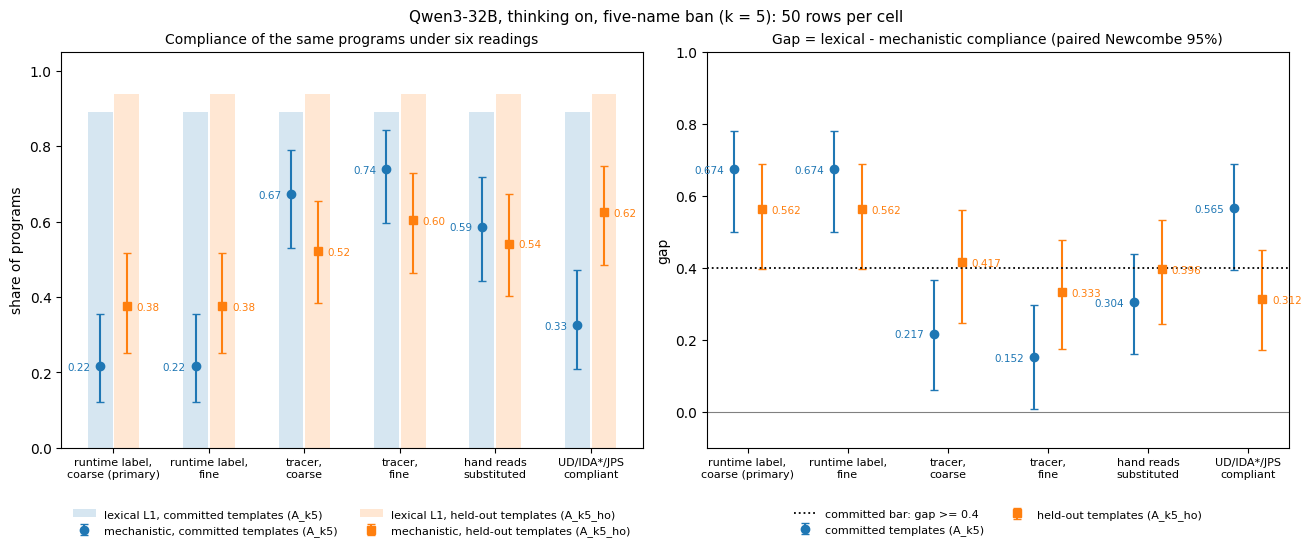

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout="constrained")
xs = np.arange(len(READINGS))
xlabels = [READING_LABEL[rd].replace(", ", ",\n").replace(" substituted", "\nsubstituted").replace(" compliant", "\ncompliant")
           for rd in READINGS]
for kk, lab, mk, off, col in (("5", "committed templates (A_k5)", "o", -0.14, "tab:blue"),
                              ("ho", "held-out templates (A_k5_ho)", "s", 0.14, "tab:orange")):
    c = s0a["cells"]["q32"][kk]
    ok = [i for i, rd in enumerate(READINGS) if c[rd]["n"]]
    lex = [c[READINGS[i]]["lex"] for i in ok]
    mech = [c[READINGS[i]]["mech"] for i in ok]
    m_lo = [c[READINGS[i]]["mech"] - c[READINGS[i]]["mech_wilson"][0] for i in ok]
    m_hi = [c[READINGS[i]]["mech_wilson"][1] - c[READINGS[i]]["mech"] for i in ok]
    axes[0].bar(xs[ok] + off, lex, width=0.26, color=col, alpha=0.18, label=f"lexical L1, {lab}")
    axes[0].errorbar(xs[ok] + off, mech, yerr=[m_lo, m_hi], fmt=mk, color=col, ms=6, capsize=3,
                     label=f"mechanistic, {lab}")
    gap = [c[READINGS[i]]["gap"] for i in ok]
    g_lo = [c[READINGS[i]]["gap"] - c[READINGS[i]]["ci"][0] for i in ok]
    g_hi = [c[READINGS[i]]["ci"][1] - c[READINGS[i]]["gap"] for i in ok]
    axes[1].errorbar(xs[ok] + off, gap, yerr=[g_lo, g_hi], fmt=mk, color=col, ms=6, capsize=3, label=lab)
    side = dict(xytext=(-7, -3), ha="right") if off < 0 else dict(xytext=(7, -3), ha="left")
    for i, y in zip(ok, mech):
        axes[0].annotate(f"{y:.2f}", (xs[i] + off, y), textcoords="offset points", fontsize=7.5, color=col, **side)
    for i, y in zip(ok, gap):
        axes[1].annotate(f"{y:.3f}", (xs[i] + off, y), textcoords="offset points", fontsize=7.5, color=col, **side)
axes[1].axhline(0.4, color="black", ls=":", lw=1.3, label="committed bar: gap >= 0.4")
axes[1].axhline(0.0, color="grey", lw=0.8)
for ax, ttl, yl in ((axes[0], "Compliance of the same programs under six readings", "share of programs"),
                    (axes[1], "Gap = lexical - mechanistic compliance (paired Newcombe 95%)", "gap")):
    ax.set_xticks(xs)
    ax.set_xticklabels(xlabels, fontsize=8)
    ax.set_title(ttl, fontsize=10)
    ax.set_ylabel(yl)
axes[0].set_ylim(0, 1.05)
axes[1].set_ylim(-0.1, 1.0)
for ax in axes:
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncols=2, frameon=False)
fig.suptitle(f"Qwen3-32B, thinking on, five-name ban (k = 5): {MAX_ROWS_PER_CELL} rows per cell", fontsize=11)
fig.savefig(FIGURES / "fig_demo_0a_readings.png", dpi=150)
plt.show()

### Where the instruments disagree

Most of the difference between the primary reading and the hand reads comes from a few runtime labels. The table cross-tabulates, for the completed programs that were read by hand, the runtime label (and its coarse class) against the reader's family (and its class). After it comes one program that the runtime label calls a banned mechanism but the reader classes as compliant, with the start of the model's reasoning.

In [23]:
read_rows = [r for cid in CELLS for r in RW.cell(cid) if r["uid"] in read_map() and completed(r) and rt_traceable(r)]
if read_rows:
    ct = pd.crosstab(pd.Series([f"{r['runtime_label']} -> {rt_class(r)}" for r in read_rows],
                               name="runtime label -> coarse class"),
                     pd.Series([f"{r['manual_read']['family']} ({FAMILY_NAME[r['manual_read']['family']]}) -> "
                                f"{FAMILY_CLASS[r['manual_read']['family']]}" for r in read_rows],
                               name="hand-read family -> read class"))
    display(ct)
flip = sorted([r for r in read_rows if rt_class(r) in A.coarse_banned(list(A.LITERAL5))
               and FAMILY_CLASS[r["manual_read"]["family"]] == "OTHER"], key=lambda r: len(r["code"] or ""))
print(f"{len(flip)} read programs are banned by the runtime label but compliant by the hand read")
if flip:
    r = flip[0]
    mr = r["manual_read"]
    print(f"\n{r['uid']} (template {r['template']}): runtime label {r['runtime_label']} -> {rt_class(r)}; "
          f"tracer {r['order_class']} / {r['order_class_fine']}; lexical L1 compliant {r['lexical_L1']}")
    print(f"hand read: {mr['algorithm']} | expansion: {mr['expansion_discipline']} | container: {mr['container']}")
    print("\nreasoning (start):", r["reasoning_excerpt"][:400].strip().replace("\n", " "), "...")
    print("\n" + r["code"])

hand-read family -> read class,BF (grid Bellman-Ford) -> OTHER,CK (coordinate-key heap) -> OTHER,FL (raster flood-fill) -> OTHER,MX (mixed deque) -> OTHER,RC (random choice) -> OTHER,RP (random-priority frontier) -> OTHER,SP (set frontier) -> OTHER,UD (unit-weight Dijkstra) -> BFS
runtime label -> coarse class,,,,,,,,
dfs -> DFS,0,0,1,2,2,0,3,0
dijkstra_unit -> BFS,0,0,0,0,0,0,0,16
iddfs -> ID,15,0,2,0,0,0,0,0
inconsistent -> OTHER,0,13,0,0,0,8,0,0


25 read programs are banned by the runtime label but compliant by the hand read

A_k5_ho|21 (template W5): runtime label dfs -> DFS; tracer OTHER / OTHER-unknown; lexical L1 compliant True
hand read: arbitrary-order graph search | expansion: set.pop() order (hash order: neither FIFO nor LIFO) | container: set frontier

reasoning (start): Okay, I need to write a Python function called solve that finds a path from a start to a goal cell on a grid. The constraints say I can't use certain algorithms like BFS, DFS, etc. Hmm, so what other method can I use?  Wait, the problem says not to use BFS, DFS, IDDFS, A*, or greedy best-first. So what's left? Maybe a different approach, like a modified version of Dijkstra's algorithm? Wait, but ...

def solve(grid, start, goal):
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    if start == goal:
        return [start]
    rows = len(grid)
    cols = len(grid[0])
    visited = set([start])
    frontier = set

## Summary

At `MAX_ROWS_PER_CELL = 50` (every row), the code above reproduces the Qwen3-32B half of item 0a exactly. The two n3 positive controls match, the Table 431b rows are identical to the artifact's, and every recorded value of `results/s0a.json` for these cells is identical.

* **The gap is instrument-dependent.** The primary runtime label finds that 10 of 46 completed programs (0.22) comply with the k = 5 ban mechanistically, while 0.89 comply lexically: a gap of 0.67 (0.50 to 0.78). The same programs score 27/46 = 0.59 with hand reads substituted (gap 0.30), 0.67 by the tracer (gap 0.22) and 0.74 by the fine tracer (gap 0.15).
* **Held-out templates.** The runtime label gives 0.38 (gap 0.56). The hand reads give 0.54, with a gap of 0.396: just under the 0.4 bar.
* **Committed bars.** Qwen3-32B meets both committed bars only under the two runtime-label readings. The tracer meets the held-out bar but not the k = 5 bar, and the UD/IDA*/JPS-compliant reading meets the k = 5 bar but not the held-out bar. The hand reads and the fine tracer meet neither.
* **Where the disagreement comes from.** 25 of the read programs are banned by the runtime label but compliant by the hand read. In 17 of them the runtime label says IDDFS, and the reader identifies grid Bellman-Ford relaxation (15) or raster flood-fill (2). The other 8 have the runtime label DFS and are read as set-frontier, random-choice, mixed-deque or flood-fill searches. The 16 unit-weight Dijkstra programs stay banned under both the runtime label and the hand reads, since unit-weight Dijkstra expands in BFS order on a unit grid; only the UD/IDA*/JPS-compliant reading counts them as compliant.

**Caveats (from the artifact).** The hand reads are one reader's, not double-coded: they are a third reading, not gold. The tracer failed its gold gate, so the tracer-based numbers are descriptive. No new sampling was done.

**Full run.** In the evaluation artifact's folder, run `uv sync`. Then point `AII_DEPS_ROOT` at a folder holding the three dependency artifacts and run `uv run eval.py all`. That runs every stage (items 0a-0k, the edits, the lint, the figures and both standard-library audits) on both models and all k, in about 4 minutes on 6 CPUs.